# FourCastNet Rainfall Accuracy for Indian Flood Events

In this notebook I check how well FourCastNet predicted the rainfall of five real flood events in India.
Each forecast is started from ERA5 data about two days before the flood, and the predicted rain is compared
with the observed rain over the same time window. At the end, the predictions are also compared with ERA5
rainfall and with IMD's gauge-based gridded rainfall for the same grid cell.

FourCastNet stores rainfall (`tp`) as a running total since the start of the forecast. So the total rain
between two times is the running total at the end minus the running total at the start, and the rain in one
6-hour step is the difference between two neighbouring values.

| City | Event | Observed rainfall | Observation window (UTC) |
|---|---|---|---|
| Mumbai | 26 Jul 2005 | 944 mm / 24h (Santacruz) | 26 Jul 03:00 -> 27 Jul 03:00 |
| Mumbai | 8 Jul 2024 | 300 mm / 6h | 7 Jul 19:30 -> 8 Jul 01:30 |
| Delhi | 9 Jul 2023 | 153 mm / 24h (Safdarjung) | 8 Jul 03:00 -> 9 Jul 03:00 |
| Chennai | 1-2 Dec 2015 | 286 mm / 24h (city average) | 1 Dec 03:00 -> 2 Dec 03:00 |
| Idukki | 15-17 Aug 2018 | 588 mm / 3 days (Periyar basin) | 14 Aug 03:00 -> 17 Aug 03:00 (assumed IMD days) |

IMD's rainfall day runs from 08:30 to 08:30 IST, which is 03:00 to 03:00 UTC.

Contents:
1. Setup
2. CDS API key
3. Flood cases
4. Running FourCastNet
5. Reading the rainfall
6. Predicted vs observed rainfall
7. Flood size vs error
8. Lead time (Mumbai 2005)
9. 6-hourly rainfall
10. Timing check for Mumbai 2024
11. Comparison with ERA5 rainfall
12. Comparison with IMD gridded rainfall

## 1. Setup

Installing `ai-models` with the FourCastNet plugin and the libraries needed to read GRIB files.

In [ ]:
!apt-get -qq install -y libeccodes0 libeccodes-dev > /dev/null
!pip -q install ai-models ai-models-fourcastnet cdsapi cfgrib xarray matplotlib "earthkit-data<1.0" scipy pandas

# PyTorch 2.6+ does not load this checkpoint by default, so set weights_only=False (file is from ECMWF's server)
import os, importlib.util
path = os.path.join(os.path.dirname(importlib.util.find_spec("ai_models_fourcastnet").origin), "model.py")
s = open(path).read()
if "weights_only=False" not in s:
    s = s.replace("torch.load(checkpoint_file, map_location=self.device)",
                  "torch.load(checkpoint_file, map_location=self.device, weights_only=False)")
    open(path, "w").write(s)
print("patched" if "weights_only=False" in open(path).read() else "PATCH FAILED", path)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.1/56.1 kB 3.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 79.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.1/49.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 398.5/398.5 kB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 362.9/362.9 kB 27.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.6/91.6 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.1/76.1 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 12.2 MB/s eta 0:00:00
   ━━━━━

After the install, I restart the runtime (`Runtime -> Restart session`) so the new package versions are loaded, and then continue from section 2.

## 2. CDS API key

ERA5 data is downloaded from the Copernicus Climate Data Store, which needs a personal API key.

In [ ]:
import os
from getpass import getpass
cds_key = getpass("Paste your CDS API key (UID:KEY): ")
with open(os.path.expanduser("~/.cdsapirc"), "w") as f:
    f.write("url: https://cds.climate.copernicus.eu/api\n")
    f.write(f"key: {cds_key}\n")
print("Wrote ~/.cdsapirc")

Paste your CDS API key (UID:KEY): ··········
Wrote ~/.cdsapirc


## 3. Flood cases

`obs_start` and `obs_end` give the observation window in UTC. The forecast length (`lead_time`) is chosen so
that the forecast covers the whole window: 60 h for Mumbai 2024 and Delhi, 78 h for Mumbai 2005 and Chennai,
and 102 h for Idukki.

In [ ]:
import pandas as pd
T = pd.Timestamp

CASES = {
    "Mumbai_2005": dict(city="Mumbai", lat=19.0760, lon=72.8777, init_date="20050724", init_time="0000", lead_time=78,
                        observed_rain_mm=944, obs_start=T("2005-07-26 03:00"), obs_end=T("2005-07-27 03:00"),
                        note="IMD Santacruz, 24h ending 08:30 IST 27 Jul"),
    "Mumbai_2024": dict(city="Mumbai", lat=19.0760, lon=72.8777, init_date="20240706", init_time="0000", lead_time=60,
                        observed_rain_mm=300, obs_start=T("2024-07-07 19:30"), obs_end=T("2024-07-08 01:30"),
                        note="IMD red alert, 01:00-07:00 IST 8 Jul"),
    "Delhi_2023":  dict(city="Delhi", lat=28.5822, lon=77.2065, init_date="20230707", init_time="0000", lead_time=60,
                        observed_rain_mm=153, obs_start=T("2023-07-08 03:00"), obs_end=T("2023-07-09 03:00"),
                        note="IMD Safdarjung, 24h ending 08:30 IST 9 Jul"),
    "Chennai_2015": dict(city="Chennai", lat=13.0827, lon=80.2707, init_date="20151129", init_time="0000", lead_time=78,
                        observed_rain_mm=286, obs_start=T("2015-12-01 03:00"), obs_end=T("2015-12-02 03:00"),
                        note="City-wide average, 24h ending 08:30 IST 2 Dec"),
    "Idukki_2018": dict(city="Idukki (Kerala)", lat=9.8400, lon=76.9764, init_date="20180813", init_time="0000", lead_time=102,
                        observed_rain_mm=588, obs_start=T("2018-08-14 03:00"), obs_end=T("2018-08-17 03:00"),
                        note="Periyar basin, 3-day total 15-17 Aug (assumed IMD days; basin vs grid cell)"),
}

## 4. Running FourCastNet

One forecast per case. The log is printed while it runs, and a case is skipped if its output file already exists.

In [ ]:
import os, subprocess

def run_fourcastnet(run_id, init_date, init_time, lead_time):
    out_path = f"fourcastnet_{run_id}_{init_date}_{init_time}_lt{lead_time}.grib"
    if os.path.exists(out_path) and os.path.getsize(out_path) > 0:
        print(f"[skip] {out_path} already exists")
        return out_path
    cmd = ["ai-models", "--download-assets", "--input", "cds",
           "--date", init_date, "--time", init_time, "--lead-time", str(lead_time),
           "--path", out_path, "fourcastnet"]
    print(f"\n===== {run_id}: {' '.join(cmd)} =====")
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in proc.stdout:
        print(line, end="")
    if proc.wait() != 0:
        if os.path.exists(out_path):
            os.remove(out_path)
        raise RuntimeError(f"ai-models failed for {run_id} -- see the log above")
    return out_path

fcn_outputs = {cid: run_fourcastnet(cid, p["init_date"], p["init_time"], p["lead_time"]) for cid, p in CASES.items()}
print("\nDone:", fcn_outputs)


===== Mumbai_2005: ai-models --download-assets --input cds --date 20050724 --time 0000 --lead-time 78 --path fourcastnet_Mumbai_2005_20050724_0000_lt78.grib fourcastnet =====
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
2026-10-10 05:40:26,091 INFO Writing results to fourcastnet_Mumbai_2005_20050724_0000_lt78.grib
2026-10-10 05:40:26,091 INFO Downloading /content/backbone.ckpt
2026-10-10 05:40:26,091 INFO Downloading https://get.ecmwf.int/repository/test-data/ai-models/fourcastnet/0.1/backbone.ckpt

backbone.ckpt:   0%|          | 0.00/862M [00:00<?, ?B/s]
backbone.ckpt:   0%|          | 1.00M/862M [00:00<08:48, 1.71MB/s]
backbone.ckpt:   0%|          | 2.00M/862M [00:00<04:37, 3.25MB/s]
backbone.ckpt:   0%|          | 4.00M/862M [00:00<02:33, 5.87MB/s]
backb

## 5. Reading the rainfall

`tp` is a running total since the forecast started, so:
- total rain over the forecast = the last value
- rain between two times = running total at the end - running total at the start (linearly interpolated inside a 6-hour step)

I also check that the running total never decreases.

In [ ]:
import numpy as np, xarray as xr

def cumulative_rain(grib_path, lat, lon):
    # running total of rain (mm) at the nearest grid cell, starting from 0 at the start time
    tp = xr.open_dataset(grib_path, engine="cfgrib",
                         backend_kwargs={"indexpath": "", "filter_by_keys": {"paramId": 228}})["tp"]
    pt = tp.sel(latitude=lat, longitude=lon, method="nearest")
    s = pd.Series(pt.values.astype(float) * 1000.0, index=pd.to_datetime(pt["valid_time"].values)).sort_index()
    init = pd.Timestamp(pt["time"].values)
    if init not in s.index:
        s.loc[init] = 0.0
    return s.sort_index()

def rain_between(cum, start, end):
    if end > cum.index.max() or start < cum.index.min():
        raise ValueError(f"forecast covers {cum.index.min()} -> {cum.index.max()}, window is {start} -> {end}")
    t0 = cum.index[0]
    t = (cum.index - t0).total_seconds()          # seconds since the start
    c = lambda x: np.interp((pd.Timestamp(x) - t0).total_seconds(), t, cum.values)
    return float(c(end) - c(start))

# check that the running total never decreases
cum = {}
for cid, path in fcn_outputs.items():
    p = CASES[cid]
    cum[cid] = cumulative_rain(path, p["lat"], p["lon"])
    attrs = xr.open_dataset(path, engine="cfgrib",
                            backend_kwargs={"indexpath": "", "filter_by_keys": {"paramId": 228}})["tp"].attrs
    print(f"{cid}: stepType={attrs.get('GRIB_stepType')}, units={attrs.get('units')}, "
          f"never decreases={bool((cum[cid].diff().dropna() >= -1e-6).all())}, "
          f"total over forecast={cum[cid].iloc[-1]:.1f} mm")

Mumbai_2005: stepType=accum, units=m, never decreases=True, total over forecast=174.5 mm
Mumbai_2024: stepType=accum, units=m, never decreases=True, total over forecast=57.4 mm
Delhi_2023: stepType=accum, units=m, never decreases=True, total over forecast=17.0 mm
Chennai_2015: stepType=accum, units=m, never decreases=True, total over forecast=120.5 mm
Idukki_2018: stepType=accum, units=m, never decreases=True, total over forecast=373.9 mm


## 6. Predicted vs observed rainfall

Predicted rain over the same window as each observation. The last column is the total over the whole forecast, for reference.

In [ ]:
rows = []
for cid, p in CASES.items():
    pred = rain_between(cum[cid], p["obs_start"], p["obs_end"])
    obs = p["observed_rain_mm"]
    rows.append({
        "Case": cid, "City": p["city"],
        "Window (UTC)": f"{p['obs_start']:%d %b %H:%M} -> {p['obs_end']:%d %b %H:%M}",
        "Observed (mm)": obs,
        "Predicted, same window (mm)": round(pred, 1),
        "Error (mm)": round(pred - obs, 1),
        "% Error": round(100 * (pred - obs) / obs, 1),
        "Abs % Error": round(abs(100 * (pred - obs) / obs), 1),
        "Predicted, whole forecast (mm)": round(cum[cid].iloc[-1], 1),
        "Note": p["note"],
    })
results_df = pd.DataFrame(rows).sort_values("Observed (mm)").reset_index(drop=True)
results_df

,Case,City,Window (UTC),Observed (mm),"Predicted, same window (mm)",Error (mm),% Error,Abs % Error,"Predicted, whole forecast (mm)",Note
0,Delhi_2023,Delhi,08 Jul 03:00 -> 09 Jul 03:00,153,10.8,-142.2,-92.9,92.9,17.0,"IMD Safdarjung, 24h ending 08:30 IST 9 Jul"
1,Chennai_2015,Chennai,01 Dec 03:00 -> 02 Dec 03:00,286,44.3,-241.7,-84.5,84.5,120.5,"City-wide average, 24h ending 08:30 IST 2 Dec"
2,Mumbai_2024,Mumbai,07 Jul 19:30 -> 08 Jul 01:30,300,6.3,-293.7,-97.9,97.9,57.4,"IMD red alert, 01:00-07:00 IST 8 Jul"
3,Idukki_2018,Idukki (Kerala),14 Aug 03:00 -> 17 Aug 03:00,588,302.8,-285.2,-48.5,48.5,373.9,"Periyar basin, 3-day total 15-17 Aug (assumed ..."
4,Mumbai_2005,Mumbai,26 Jul 03:00 -> 27 Jul 03:00,944,59.8,-884.2,-93.7,93.7,174.5,"IMD Santacruz, 24h ending 08:30 IST 27 Jul"


## 7. Flood size vs error

Pearson correlation between the observed rainfall (flood size) and the absolute percentage error.

Pearson (observed rainfall vs abs % error, same-window): r = -0.192, p = 0.757, n = 5


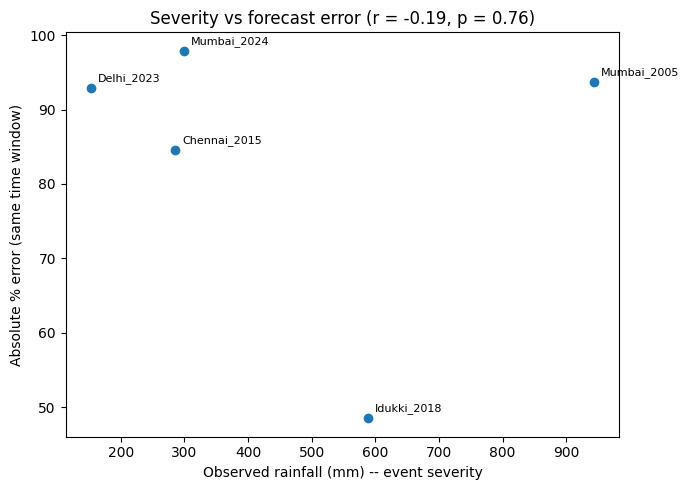

In [ ]:
import matplotlib.pyplot as plt
from scipy import stats

corr, p_value = stats.pearsonr(results_df["Observed (mm)"], results_df["Abs % Error"])
print(f"Pearson (observed rainfall vs abs % error, same-window): r = {corr:.3f}, p = {p_value:.3f}, n = {len(results_df)}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(results_df["Observed (mm)"], results_df["Abs % Error"])
for _, r in results_df.iterrows():
    ax.annotate(r["Case"], (r["Observed (mm)"], r["Abs % Error"]), fontsize=8, xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("Observed rainfall (mm) -- event severity")
ax.set_ylabel("Absolute % error (same time window)")
ax.set_title(f"Severity vs forecast error (r = {corr:.2f}, p = {p_value:.2f})")
plt.tight_layout(); plt.savefig("severity_vs_error.png", dpi=150); plt.show()

With only 5 events, this correlation is only an indication and not statistically strong.

## 8. Lead time (Mumbai 2005)

The Mumbai 2005 forecast is started 1, 2, 3 and 5 days before the flood. The rain is always measured over the
same flood-day window (26 Jul 03:00 -> 27 Jul 03:00 UTC), so only the start date changes. The 2-days-before run
is the same as the main case, so it is reused.


===== Mumbai_2005: ai-models --download-assets --input cds --date 20050725 --time 0000 --lead-time 54 --path fourcastnet_Mumbai_2005_20050725_0000_lt54.grib fourcastnet =====
/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
2026-10-10 05:47:30,807 INFO Writing results to fourcastnet_Mumbai_2005_20050725_0000_lt54.grib
2026-10-10 05:47:30,807 INFO Loading ./global_means.npy
2026-10-10 05:47:30,808 INFO Loading ./global_stds.npy
2026-10-10 05:47:30,808 INFO Loading surface fields from CDS
2026-10-10 05:47:31,067 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the upda

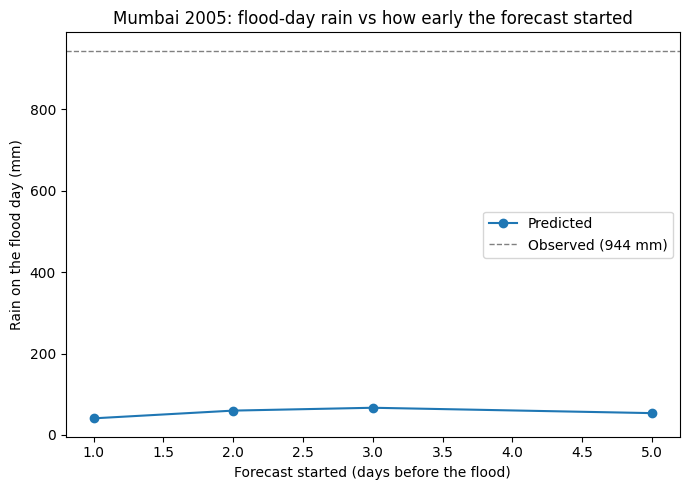

,Started (days before),Init date,Hours ahead (to window end),Predicted flood-day rain (mm),% Error vs 944 mm
0,1,20050725,51,40.8,-95.7
1,2,20050724,75,59.8,-93.7
2,3,20050723,99,66.8,-92.9
3,5,20050721,147,53.6,-94.3


In [ ]:
base = CASES["Mumbai_2005"]
starts = {1: ("20050725", 54), 2: ("20050724", 78), 3: ("20050723", 102), 5: ("20050721", 150)}

lt_rows = []
for days, (init_date, lead) in starts.items():
    path = run_fourcastnet("Mumbai_2005", init_date, "0000", lead)
    c = cumulative_rain(path, base["lat"], base["lon"])
    pred = rain_between(c, base["obs_start"], base["obs_end"])
    lead_to_window_end = int((base["obs_end"] - pd.Timestamp(init_date)).total_seconds() // 3600)
    lt_rows.append({"Started (days before)": days, "Init date": init_date,
                    "Hours ahead (to window end)": lead_to_window_end,
                    "Predicted flood-day rain (mm)": round(pred, 1),
                    "% Error vs 944 mm": round(100 * (pred - 944) / 944, 1)})
lt_df = pd.DataFrame(lt_rows).sort_values("Started (days before)")

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(lt_df["Started (days before)"], lt_df["Predicted flood-day rain (mm)"], marker="o", label="Predicted")
ax.axhline(944, color="gray", linestyle="--", linewidth=1, label="Observed (944 mm)")
ax.set_xlabel("Forecast started (days before the flood)")
ax.set_ylabel("Rain on the flood day (mm)")
ax.set_title("Mumbai 2005: flood-day rain vs how early the forecast started")
ax.legend(); plt.tight_layout(); plt.savefig("leadtime_sensitivity.png", dpi=150); plt.show()
lt_df

## 9. 6-hourly rainfall

Rain in each 6-hour step (difference of running totals) for every case.

In [ ]:
slice_rows = []
for cid, c in cum.items():
    rain = c.diff().fillna(0.0)
    for vt, mm in rain.items():
        slice_rows.append({"City": CASES[cid]["city"], "Case": cid,
                           "Forecast hour": int((vt - c.index[0]).total_seconds() // 3600),
                           "Valid time (UTC)": vt,
                           "Rain in 6 h ending here (mm)": round(mm, 1),
                           "Cumulative (mm)": round(c[vt], 1)})
slices_df = pd.DataFrame(slice_rows).sort_values(["City", "Case", "Forecast hour"]).reset_index(drop=True)
slices_df

,City,Case,Forecast hour,Valid time (UTC),Rain in 6 h ending here (mm),Cumulative (mm)
0,Chennai,Chennai_2015,0,2015-11-29 00:00:00,0.0,0.0
1,Chennai,Chennai_2015,6,2015-11-29 06:00:00,4.8,4.8
2,Chennai,Chennai_2015,12,2015-11-29 12:00:00,8.2,13.0
3,Chennai,Chennai_2015,18,2015-11-29 18:00:00,6.5,19.5
4,Chennai,Chennai_2015,24,2015-11-30 00:00:00,6.7,26.2
...,...,...,...,...,...,...
63,Mumbai,Mumbai_2024,36,2024-07-07 12:00:00,5.1,29.6
64,Mumbai,Mumbai_2024,42,2024-07-07 18:00:00,5.4,35.0
65,Mumbai,Mumbai_2024,48,2024-07-08 00:00:00,5.7,40.7
66,Mumbai,Mumbai_2024,54,2024-07-08 06:00:00,8.1,48.8


## 10. Timing check for Mumbai 2024

The heavy rain in Mumbai 2024 fell between 01:00 and 07:00 IST. Here I check how much rain the model put in that window and when its wettest 6 hours were.

In [ ]:
c = cum["Mumbai_2024"]; rain = c.diff().dropna()
peak_end = rain.idxmax()
print(f"Observed burst: 7 Jul 19:30 -> 8 Jul 01:30 UTC, 300 mm")
print(f"Model rain in that window: {rain_between(c, CASES['Mumbai_2024']['obs_start'], CASES['Mumbai_2024']['obs_end']):.1f} mm")
print(f"Model's wettest 6 h: {peak_end - pd.Timedelta(hours=6):%d %b %H:%M} -> {peak_end:%d %b %H:%M} UTC, {rain.max():.1f} mm")
print(f"Note: forecast ends {c.index.max():%d %b %H:%M} UTC; if the wettest slice is the last one, the true peak may be later.")

Observed burst: 7 Jul 19:30 -> 8 Jul 01:30 UTC, 300 mm
Model rain in that window: 6.3 mm
Model's wettest 6 h: 08 Jul 06:00 -> 08 Jul 12:00 UTC, 8.7 mm
Note: forecast ends 08 Jul 12:00 UTC; if the wettest slice is the last one, the true peak may be later.


## 11. Comparison with ERA5 rainfall

FourCastNet learned rainfall from ERA5, so here I download ERA5 hourly rainfall for the same grid cell and window.
This separates the model's own error (FourCastNet vs ERA5) from the error already in ERA5 (ERA5 vs gauge).
The Mumbai 2024 window starts and ends at :30, so for ERA5 (hourly) it is off by half an hour at each end.

In [ ]:
!pip -q install netCDF4
import cdsapi, xarray as xr, pandas as pd, numpy as np

c = cdsapi.Client()
era_rows = []
for cid, p in CASES.items():
    days = pd.date_range(p["obs_start"].normalize(), p["obs_end"].normalize(), freq="D")
    fn = f"era5_tp_{cid}.nc"
    c.retrieve("reanalysis-era5-single-levels", {
        "product_type": ["reanalysis"], "variable": ["total_precipitation"],
        "year": sorted({f"{d.year}" for d in days}), "month": sorted({f"{d.month:02d}" for d in days}),
        "day": sorted({f"{d.day:02d}" for d in days}), "time": [f"{h:02d}:00" for h in range(24)],
        "area": [p["lat"] + 0.5, p["lon"] - 0.5, p["lat"] - 0.5, p["lon"] + 0.5],
        "data_format": "netcdf", "download_format": "unarchived"}, fn)
    ds = xr.open_dataset(fn)
    tp = ds["tp"].sel(latitude=p["lat"], longitude=p["lon"], method="nearest")
    s = pd.Series(tp.values * 1000.0, index=pd.to_datetime(tp["valid_time"].values))   # mm in the hour ending at each time
    era5 = s[(s.index > p["obs_start"]) & (s.index <= p["obs_end"])].sum()
    fcn = results_df.set_index("Case").loc[cid, "Predicted, same window (mm)"]
    era_rows.append({"Case": cid, "Observed gauge (mm)": p["observed_rain_mm"],
                     "ERA5, same grid cell (mm)": round(era5, 1),
                     "FourCastNet (mm)": fcn,
                     "FourCastNet vs ERA5 (%)": round(100 * (fcn - era5) / era5, 1) if era5 > 0 else np.nan,
                     "ERA5 vs gauge (%)": round(100 * (era5 - p["observed_rain_mm"]) / p["observed_rain_mm"], 1)})
pd.DataFrame(era_rows)

2026-10-10 05:52:00,827 INFO [2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 October 2026.
 **[More information about the upcoming change.](https://forum.ecmwf.int/t/upcoming-cds-terms-of-use-change/15374)**
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] The [CDS Terms of Use](https://cds.climate.copernicus.eu/disclaimer-privacy) will be updated on 28 October 2026. Continued use of Copernicus Products and Services through the CDS after this date constitutes acceptance of the updated terms. If you do not accept the change, please [contact ECMWF Support](https://jira.ecmwf.int/plugins/servlet/desk/portal/1/create/202) before 27 

3521894f79e99424bda16f14e2a35c3.nc:   0%|          | 0.00/26.8k [00:00<?, ?B/s]

2026-10-10 05:52:35,248 INFO Request ID is f026a23e-8d27-43cc-bbe6-3a5d80519b30
INFO:ecmwf.datastores.legacy_client:Request ID is f026a23e-8d27-43cc-bbe6-3a5d80519b30
2026-10-10 05:52:35,306 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2026-10-10 05:53:09,331 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


3dee8aafb0d9b9a4eabaffc224ba4065.nc:   0%|          | 0.00/26.5k [00:00<?, ?B/s]

2026-10-10 05:53:11,910 INFO Request ID is 9d0dd1e6-1e0c-4ad7-bf67-c3361eb14056
INFO:ecmwf.datastores.legacy_client:Request ID is 9d0dd1e6-1e0c-4ad7-bf67-c3361eb14056
2026-10-10 05:53:11,952 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2026-10-10 05:55:09,643 INFO status has been updated to running
INFO:ecmwf.datastores.legacy_client:status has been updated to running
2026-10-10 05:56:07,478 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


...

2026-10-10 05:56:08,583 INFO Request ID is 7692a262-4024-414a-8633-2f7ed5a7a0d4
INFO:ecmwf.datastores.legacy_client:Request ID is 7692a262-4024-414a-8633-2f7ed5a7a0d4
2026-10-10 05:56:08,853 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2026-10-10 05:56:33,168 INFO status has been updated to running
INFO:ecmwf.datastores.legacy_client:status has been updated to running
2026-10-10 05:56:44,608 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


a9a71b288bc2460d9ef3993826b270c3.nc:   0%|          | 0.00/26.7k [00:00<?, ?B/s]

2026-10-10 05:56:45,305 INFO Request ID is ffede6da-6320-47e9-a018-9fdf0707eb54
INFO:ecmwf.datastores.legacy_client:Request ID is ffede6da-6320-47e9-a018-9fdf0707eb54
2026-10-10 05:56:45,347 INFO status has been updated to accepted
INFO:ecmwf.datastores.legacy_client:status has been updated to accepted
2026-10-10 05:57:08,503 INFO status has been updated to running
INFO:ecmwf.datastores.legacy_client:status has been updated to running
2026-10-10 05:57:38,906 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successful


73ec694128e9fd5d757b43791e4357ef.nc:   0%|          | 0.00/29.9k [00:00<?, ?B/s]

,Case,Observed gauge (mm),"ERA5, same grid cell (mm)",FourCastNet (mm),FourCastNet vs ERA5 (%),ERA5 vs gauge (%)
0,Mumbai_2005,944,74.300003,59.8,-19.5,-92.1
1,Mumbai_2024,300,2.500000,6.3,154.3,-99.2
2,Delhi_2023,153,34.900002,10.8,-69.1,-77.2
3,Chennai_2015,286,50.599998,44.3,-12.5,-82.3
4,Idukki_2018,588,314.899994,302.8,-3.9,-46.4


## 12. Comparison with IMD gridded rainfall

IMD's gridded rainfall is built from rain gauges and uses the same 0.25 deg grid as the model, so it is a fairer
reference than a single gauge. IMD's website could not be reached from Colab, so I downloaded the binary files
for each year from the IMD Pune site and uploaded them here. They are read with the `imdlib` package.

In [ ]:
!pip -q install --no-deps imdlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 77.6 MB/s eta 0:00:00


Uploading the four yearly files (2005, 2015, 2018, 2023). Each file is renamed to the name `imdlib` expects.

In [ ]:
import os, re, shutil
from google.colab import files
os.makedirs("imd_data/rain", exist_ok=True)
for name in files.upload():
    year = re.search(r"(19|20)\d{2}", name).group(0)
    target = f"imd_data/rain/Rainfall_ind{year}_rfp25.grd"
    shutil.move(name, target)
    print(f"{name} -> {target} ({os.path.getsize(target)/1e6:.1f} MB)")

Saving Rainfall_ind2005_rfp25.grd to Rainfall_ind2005_rfp25.grd
Saving Rainfall_ind2015_rfp25.grd to Rainfall_ind2015_rfp25.grd
Saving Rainfall_ind2018_rfp25.grd to Rainfall_ind2018_rfp25.grd
Saving Rainfall_ind2023_rfp25.grd to Rainfall_ind2023_rfp25.grd
Rainfall_ind2005_rfp25.grd -> imd_data/rain/Rainfall_ind2005_rfp25.grd (25.4 MB)
Rainfall_ind2015_rfp25.grd -> imd_data/rain/Rainfall_ind2015_rfp25.grd (25.4 MB)
Rainfall_ind2018_rfp25.grd -> imd_data/rain/Rainfall_ind2018_rfp25.grd (25.4 MB)
Rainfall_ind2023_rfp25.grd -> imd_data/rain/Rainfall_ind2023_rfp25.grd (25.4 MB)


The comparison table: reported rainfall, IMD grid, ERA5 and FourCastNet for each case.

In [ ]:
# IMD gridded rainfall: daily values from about 7,000 IMD rain gauges on a 0.25 deg grid (same cells as the model)
# An IMD day covers 08:30 IST to 08:30 IST (03:00 to 03:00 UTC)
# IMD labels each day with the date of the morning it is measured (the end of the 24 h), so this is False
IMD_LABEL_IS_START = False

import os, imdlib, numpy as np, pandas as pd

os.makedirs("imd_data", exist_ok=True)
def is_daily_window(p):
    return all(t.hour == 3 and t.minute == 0 for t in (p["obs_start"], p["obs_end"]))

years = sorted({p["obs_start"].year for p in CASES.values() if is_daily_window(p)})
imd = {}
for y in years:
    print(f"Reading IMD gridded rainfall for {y} from imd_data/rain/ ...")
    obj = imdlib.open_data("rain", y, y, None, "imd_data")   # reads the uploaded Rainfall_ind{y}_rfp25.grd file
    ds = obj.get_xarray()
    imd[y] = ds[list(ds.data_vars)[0]]

def imd_cell_series(da, lat, lon):
    """Daily rain at the nearest grid cell (uses the nearest land cell if that one has no data, e.g. sea)."""
    box = da.sel(lat=slice(lat - 0.3, lat + 0.3), lon=slice(lon - 0.3, lon + 0.3))
    valid = box.notnull().any("time")
    best, best_d = None, 1e9
    for la in box.lat.values:
        for lo in box.lon.values:
            if bool(valid.sel(lat=la, lon=lo)):
                d = (la - lat) ** 2 + (lo - lon) ** 2
                if d < best_d:
                    best, best_d = (la, lo), d
    if best is None:
        raise ValueError(f"No valid IMD cell near {lat}, {lon}")
    s = box.sel(lat=best[0], lon=best[1]).to_series()
    s.index = pd.to_datetime(s.index)
    return s, best

imd_rows = []
for cid, p in CASES.items():
    start, end = p["obs_start"], p["obs_end"]
    if is_daily_window(p):
        s, cell = imd_cell_series(imd[start.year], p["lat"], p["lon"])
        first = start.normalize() if IMD_LABEL_IS_START else start.normalize() + pd.Timedelta(days=1)
        n_days = int((end - start) / pd.Timedelta(days=1))
        days = pd.date_range(first, periods=n_days, freq="D")
        imd_mm = float(s.reindex(days).sum(min_count=n_days))
        imd_note = f"IMD days {days[0]:%d %b} to {days[-1]:%d %b}"
    else:
        imd_mm, cell, imd_note = np.nan, None, "observation window is shorter than one IMD day -- not comparable"
    fcn = float(results_df.set_index("Case").loc[cid, "Predicted, same window (mm)"])
    gauge = p["observed_rain_mm"]
    pct = lambda a, b: round(100 * (a - b) / b, 1) if (b and not np.isnan(b)) else np.nan
    imd_rows.append({
        "Case": cid,
        "Gauge / reported (mm)": gauge,
        "IMD gridded, same cell (mm)": None if np.isnan(imd_mm) else round(imd_mm, 1),
        "FourCastNet (mm)": round(fcn, 1),
        "FourCastNet vs IMD grid (%)": pct(fcn, imd_mm),
        "IMD grid vs gauge (%)": pct(imd_mm, gauge),
        "IMD cell used": f"{cell[0]:.2f}N, {cell[1]:.2f}E" if cell else "-",
        "Note": imd_note,
    })

imd_df = pd.DataFrame(imd_rows)

# add the ERA5 values from section 11 to the same table
try:
    era_df = pd.DataFrame(era_rows)[["Case", "ERA5, same grid cell (mm)"]]
    imd_df = imd_df.merge(era_df, on="Case", how="left")
    imd_df["FourCastNet vs ERA5 (%)"] = (100 * (imd_df["FourCastNet (mm)"] - imd_df["ERA5, same grid cell (mm)"])
                                        / imd_df["ERA5, same grid cell (mm)"]).round(1)
except NameError:
    print("(ERA5 comparison cell not run -- showing gauge, IMD and FourCastNet only)")

imd_df

Reading IMD gridded rainfall for 2005 from imd_data/rain/ ...
Reading IMD gridded rainfall for 2015 from imd_data/rain/ ...
Reading IMD gridded rainfall for 2018 from imd_data/rain/ ...
Reading IMD gridded rainfall for 2023 from imd_data/rain/ ...


,Case,Gauge / reported (mm),"IMD gridded, same cell (mm)",FourCastNet (mm),FourCastNet vs IMD grid (%),IMD grid vs gauge (%),IMD cell used,Note,"ERA5, same grid cell (mm)",FourCastNet vs ERA5 (%)
0,Mumbai_2005,944,423.4,59.8,-85.9,-55.1,"19.00N, 73.00E",IMD days 27 Jul to 27 Jul,74.300003,-19.5
1,Mumbai_2024,300,NaN,6.3,NaN,NaN,-,observation window is shorter than one IMD day...,2.500000,152.0
2,Delhi_2023,153,61.4,10.8,-82.4,-59.9,"28.50N, 77.25E",IMD days 09 Jul to 09 Jul,34.900002,-69.1
3,Chennai_2015,286,329.3,44.3,-86.5,15.2,"13.25N, 80.25E",IMD days 02 Dec to 02 Dec,50.599998,-12.5
4,Idukki_2018,588,455.5,302.8,-33.5,-22.5,"9.75N, 77.00E",IMD days 15 Aug to 17 Aug,314.899994,-3.8


Daily IMD rainfall around each event, to check that the biggest day lines up with the dates used above.

In [ ]:
for cid, p in CASES.items():
    if not is_daily_window(p):
        continue
    s, cell = imd_cell_series(imd[p["obs_start"].year], p["lat"], p["lon"])
    d0 = p["obs_start"].normalize()
    print(f"\n{cid} (cell {cell[0]:.2f}N {cell[1]:.2f}E):")
    print(s.loc[d0 - pd.Timedelta(days=2): p["obs_end"].normalize() + pd.Timedelta(days=2)].round(1).to_string())


Mumbai_2005 (cell 19.00N 73.00E):
time
2005-07-24      8.5
2005-07-25     14.2
2005-07-26     10.2
2005-07-27    423.4
2005-07-28     22.3
2005-07-29     21.4
Freq: D

Delhi_2023 (cell 28.50N 77.25E):
time
2023-07-06    10.3
2023-07-07    11.6
2023-07-08     2.7
2023-07-09    61.4
2023-07-10    30.0
2023-07-11    11.9
Freq: D

Chennai_2015 (cell 13.25N 80.25E):
time
2015-11-29      2.8
2015-11-30     32.9
2015-12-01     72.3
2015-12-02    329.3
2015-12-03      6.6
2015-12-04     15.4
Freq: D

Idukki_2018 (cell 9.75N 77.00E):
time
2018-08-12      9.6
2018-08-13     53.6
2018-08-14     93.3
2018-08-15    153.3
2018-08-16    201.8
2018-08-17    100.4
2018-08-18     58.7
2018-08-19     32.7
Freq: D


## Summary

- Section 6 gives the main result: predicted vs observed rain over the same window for all five events.
- Section 7 checks whether the error depends on flood size.
- Section 8 checks whether starting the forecast earlier or later changes the result.
- Sections 9 and 10 show when the model expected rain, and whether it caught the timing of the Mumbai 2024 burst.
- Sections 11 and 12 compare the same windows with ERA5 rainfall (what FourCastNet was trained on) and with IMD's gauge-based grid, to see how much of the error comes from the model and how much from the training data.
- Limitations: a 25 km grid cell is compared with single gauges, a city average and a basin total; the Idukki window is assumed; Mumbai 2024 cannot be compared with the daily IMD grid; only five events.